# Social Media Engagement Analytics Using Python
### Data Analytics — Module-End Assignment 5

**Objective:** Import, clean, explore, transform, statistically analyse, visualise, and interpret social media engagement data using Python.

**Dataset required:** `social_media_engagement_5000.csv`

> **Before running:** Place the CSV file in the same folder as this notebook. Run the cells from top to bottom. Where the dataset uses different column names, the notebook attempts to identify common alternatives and prints the columns it finds. Review the printed column names if any analysis column is unavailable.

## Contents
1. Data import and setup
2. Data cleaning
3. Data exploration using Pandas
4. Data wrangling and feature engineering
5. Statistical analysis
6. Data visualisation (Matplotlib, Seaborn, Plotly)
7. Final insights and one-page summary

## Task 1 — Data Import & Setup
Import the libraries, load the CSV, inspect the structure, convert date columns, and perform basic NumPy array operations.

In [16]:
import warnings
warnings.filterwarnings("ignore")

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid")

file_path = "social_media_engagement_5000.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully.
Rows and columns: (5000, 19)


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [17]:
print("Column names:")
print(df.columns.tolist())

print("\\nData types before conversion:")
display(df.dtypes.to_frame("Data Type"))

# Convert columns whose names suggest they contain dates or timestamps.
date_columns = [col for col in df.columns if any(word in col.lower() for word in ["date", "time_stamp", "timestamp", "published"])]
for col in date_columns:
    converted = pd.to_datetime(df[col], errors="coerce")
    # Keep the conversion when it produces at least one valid date.
    if converted.notna().any():
        df[col] = converted

print("\\nData types after date conversion:")
display(df.dtypes.to_frame("Data Type"))

# Basic NumPy array operations using the first numeric column available.
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
if numeric_columns:
    sample_array = df[numeric_columns[0]].dropna().to_numpy()
    print(f"NumPy example using '{numeric_columns[0]}':")
    print("First 10 values:", sample_array[:10])
    print("Array size:", sample_array.size)
    if sample_array.size:
        print("Mean:", np.mean(sample_array))
        print("Minimum:", np.min(sample_array))
        print("Maximum:", np.max(sample_array))
else:
    print("No numeric columns were detected for the NumPy example.")

Column names:
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate']
\nData types before conversion:


,Data Type
user_id,int64
age,float64
gender,str
country,str
post_id,int64
post_type,str
post_category,str
likes,float64
comments,float64
shares,float64


\nData types after date conversion:


,Data Type
user_id,int64
age,float64
gender,str
country,str
post_id,int64
post_type,str
post_category,str
likes,float64
comments,float64
shares,float64


NumPy example using 'user_id':
First 10 values: [25795 10860 86820 64886 16265 92386 47194 97498 54131 70263]
Array size: 5000
Mean: 54561.8908
Minimum: 10055
Maximum: 99963


## Task 2 — Data Cleaning
Detect missing values, demonstrate suitable missing-value handling, remove duplicates, standardise text categories, check unrealistic engagement values, extract hashtag counts, and clean sentiment labels.

In [18]:
print("Missing values by column (isnull):")
display(df.isnull().sum().to_frame("Missing Values"))

print("Total missing values using isna():", int(df.isna().sum().sum()))
print("Duplicate rows before cleaning:", int(df.duplicated().sum()))

# Remove exact duplicate rows.
df = df.drop_duplicates().copy()
print("Duplicate rows after cleaning:", int(df.duplicated().sum()))

# Standardise whitespace and case for text/categorical columns.
text_columns = df.select_dtypes(include=["object", "string"]).columns.tolist()
for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

# Standardise common category fields without changing non-text data.
for col in text_columns:
    if any(word in col.lower() for word in ["gender", "sentiment", "post_type", "post type", "category", "device", "country"]):
        df[col] = df[col].str.lower().str.replace(r"\\s+", " ", regex=True)

# Fill numeric missing values with the median; fill categorical missing values with the mode.
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
for col in numeric_columns:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

categorical_columns = df.select_dtypes(include=["object", "string", "category"]).columns.tolist()
for col in categorical_columns:
    if df[col].isna().any():
        modes = df[col].mode(dropna=True)
        if not modes.empty:
            df[col] = df[col].fillna(modes.iloc[0])
        else:
            df[col] = df[col].fillna("unknown")

print("Missing values after median/mode handling:")
display(df.isna().sum().to_frame("Missing Values"))

Missing values by column (isnull):


,Missing Values
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


Total missing values using isna(): 900
Duplicate rows before cleaning: 0
Duplicate rows after cleaning: 0
Missing values after median/mode handling:


,Missing Values
user_id,0
age,0
gender,0
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


In [19]:
# Examples of forward-fill and backward-fill methods.
# These are demonstrated on a copy so they do not overwrite the median/mode-cleaned dataset.
if numeric_columns:
    example_col = numeric_columns[0]
    fill_demo = df[[example_col]].copy()
    print(f"Forward-fill and backward-fill demonstration for '{example_col}':")
    display(pd.DataFrame({
        "Original": fill_demo[example_col],
        "Forward Fill": fill_demo[example_col].ffill(),
        "Backward Fill": fill_demo[example_col].bfill()
    }).head(10))
else:
    print("No numeric column available for the fill demonstration.")

Forward-fill and backward-fill demonstration for 'user_id':


,Original,Forward Fill,Backward Fill
0,25795,25795,25795
1,10860,10860,10860
2,86820,86820,86820
3,64886,64886,64886
4,16265,16265,16265
5,92386,92386,92386
6,47194,47194,47194
7,97498,97498,97498
8,54131,54131,54131
9,70263,70263,70263


In [20]:
# Convert numeric-looking columns where a safe conversion is possible.
for col in df.columns:
    if df[col].dtype == "object":
        converted = pd.to_numeric(df[col].astype(str).str.replace(",", "", regex=False), errors="coerce")
        non_missing_original = df[col].notna().sum()
        if non_missing_original and converted.notna().sum() / non_missing_original >= 0.9:
            df[col] = converted

# Correct impossible negative values for common count/metric columns.
count_keywords = ["like", "comment", "share", "impression", "watch_time", "watch time", "follower"]
for col in df.select_dtypes(include=np.number).columns:
    if any(keyword in col.lower() for keyword in count_keywords):
        negative_count = int((df[col] < 0).sum())
        if negative_count:
            print(f"Setting {negative_count} negative value(s) in '{col}' to NaN.")
            df.loc[df[col] < 0, col] = np.nan
            df[col] = df[col].fillna(df[col].median())

# Standardise sentiment values where a sentiment column exists.
sentiment_cols = [c for c in df.columns if "sentiment" in c.lower()]
for col in sentiment_cols:
    df[col] = df[col].astype("string").str.strip().str.lower()
    df[col] = df[col].replace({
        "positive ": "positive", "pos": "positive",
        "negative ": "negative", "neg": "negative",
        "neutral ": "neutral", "neu": "neutral"
    })

# Extract hashtag count from a hashtag/text column if one exists.
hashtag_source_cols = [c for c in df.columns if "hashtag" in c.lower()]
text_source_cols = [c for c in df.columns if any(word in c.lower() for word in ["caption", "content", "text", "description"])]
source_col = hashtag_source_cols[0] if hashtag_source_cols else (text_source_cols[0] if text_source_cols else None)

if source_col:
    df["hashtag_count"] = df[source_col].astype("string").str.count(r"(?<!\w)#[A-Za-z0-9_]+").fillna(0).astype(int)
    print(f"Created 'hashtag_count' from '{source_col}'.")
else:
    print("No hashtag/text column found; hashtag_count was not created.")

print("Cleaned dataset shape:", df.shape)
display(df.head())

Created 'hashtag_count' from 'hashtags'.
Cleaned dataset shape: (5000, 20)


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,male,brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,uk,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,france,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,other,uk,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372,1


## Task 3 — Data Exploration using Pandas
Inspect the dataset, calculate summary statistics, examine categorical distributions, create a correlation matrix, and group metrics by category.

In [21]:
print("First five rows:")
display(df.head())

print("Last five rows:")
display(df.tail())

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

print("\\nDataset information:")
df.info()

print("\\nNumeric summary statistics:")
display(df.describe())

print("\\nCategorical summary statistics:")
display(df.describe(include=["object", "string", "category"]))

First five rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,male,brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,uk,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,france,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,other,uk,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372,1


Last five rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,male,australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,other,uae,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63.0,female,usa,273595,text,travel,13487.0,1497.0,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,female,germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,other,japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,04-03-2023,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


Shape: (5000, 20)
Columns: ['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']
\nDataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               5000 non-null   float64
 2   gender            5000 non-null   string 
 3   country           5000 non-null   string 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   string 
 6   post_category     5000 non-null   string 
 7   likes             5000 non-null   float64
 8   comments          5000 non-null   float64
 9   shares            5000 non-null   float64
 10  watch_time_se

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,393698.224800,0.964356,1.998600
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,230927.884535,5.318029,0.812853
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,799533.000000,191.504348,3.000000


\nCategorical summary statistics:


,gender,country,post_type,post_category,posted_at,device_type,sentiment,hashtags
count,5000,5000,5000,5000,5000,5000,5000,5000
unique,3,10,4,8,729,3,3,761
top,male,india,reel,fitness,26-12-2023,mobile,positive,#tech
freq,1849,535,1283,675,16,1684,2513,201


In [22]:
for col in df.select_dtypes(include=["object", "string", "category"]).columns:
    print(f"\\nColumn: {col}")
    print("Unique values:", df[col].unique()[:20])
    print("Number of unique values:", df[col].nunique())
    display(df[col].value_counts(dropna=False).head(15).to_frame("Count"))

\nColumn: gender
Unique values: <ArrowStringArray>
['female', 'male', 'other']
Length: 3, dtype: string
Number of unique values: 3


,Count
gender,
male,1849
other,1581
female,1570


\nColumn: country
Unique values: <ArrowStringArray>
[   'brazil',        'uk',    'france',    'canada',     'japan', 'australia',
     'india',       'uae',   'germany',       'usa']
Length: 10, dtype: string
Number of unique values: 10


,Count
country,
india,535
canada,513
brazil,504
uae,503
usa,501
france,496
uk,493
australia,493
germany,490


\nColumn: post_type
Unique values: <ArrowStringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: string
Number of unique values: 4


...

,Count
device_type,
mobile,1684
tablet,1658
desktop,1658


\nColumn: sentiment
Unique values: <ArrowStringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: string
Number of unique values: 3


,Count
sentiment,
positive,2513
neutral,1527
negative,960


\nColumn: hashtags
Unique values: <ArrowStringArray>
[   '#foodie #travel #love',                 '#fitness',
                  '#foodie',      '#music #foodie #fun',
                  '#travel',                   '#music',
  '#travel #music #fitness',     '#music #fun #fitness',
         '#lifestyle #love',                    '#tech',
      '#fun #fashion #love',       '#foodie #lifestyle',
         '#foodie #fashion',                   '#reels',
  '#foodie #fun #lifestyle',  '#love #fashion #fitness',
 '#foodie #travel #fitness',         '#foodie #fitness',
                     '#fun',          '#reels #fashion']
Length: 20, dtype: string
Number of unique values: 761


,Count
hashtags,
#tech,201
#love,176
#fitness,174
#music,165
#fun,163
#travel,162
#fashion,159
#lifestyle,156
#reels,155


,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036322,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093520,-0.002190
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


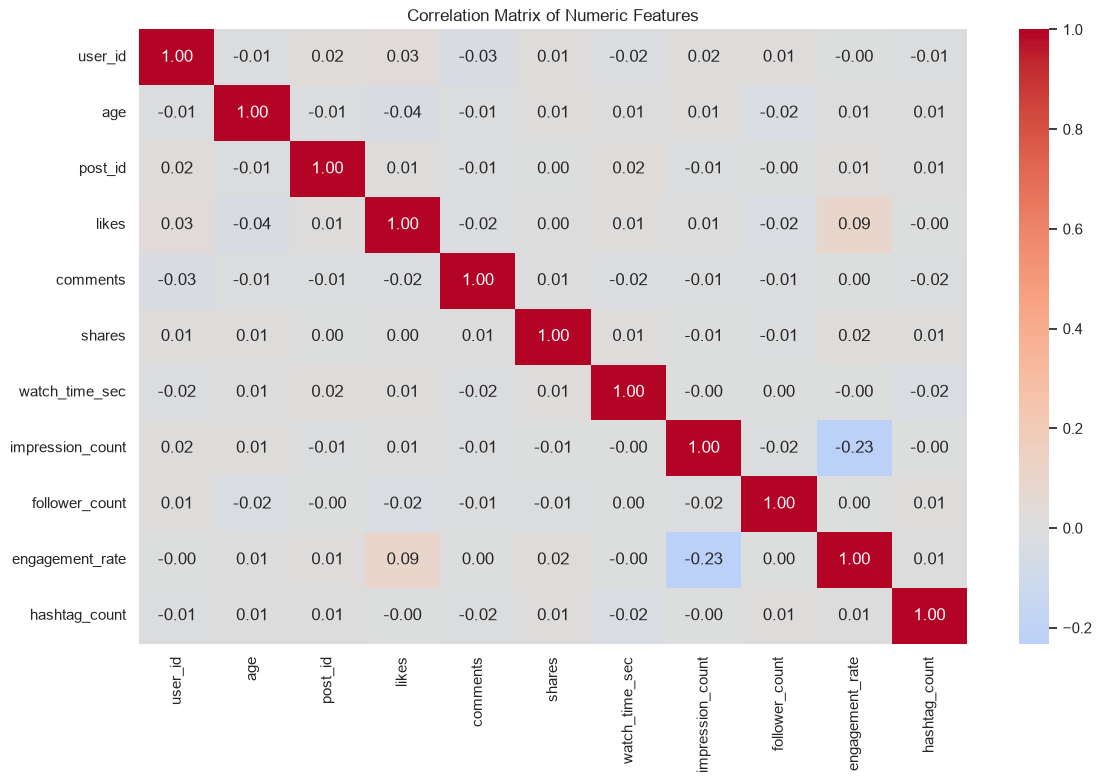

In [23]:
numeric_df = df.select_dtypes(include=np.number)
if numeric_df.shape[1] >= 2:
    correlation_matrix = numeric_df.corr(numeric_only=True)
    display(correlation_matrix)
    plt.figure(figsize=(12, 8))
    sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation Matrix of Numeric Features")
    plt.tight_layout()
    plt.show()
else:
    correlation_matrix = pd.DataFrame()
    print("At least two numeric columns are required for a correlation matrix.")

## Task 4 — Data Wrangling
Create an engagement score and optional log-transformed metrics. Produce group summaries by post type, country, and sentiment. Merge/concat/join is demonstrated only when a useful grouping table can be created.

In [24]:
def find_column(keywords, columns=None):
    columns = list(df.columns if columns is None else columns)
    for keyword in keywords:
        for col in columns:
            if keyword in col.lower().replace(" ", "_"):
                return col
    return None

likes_col = find_column(["likes", "like_count"])
comments_col = find_column(["comments", "comment_count"])
shares_col = find_column(["shares", "share_count"])
impressions_col = find_column(["impressions", "impression_count"])
post_type_col = find_column(["post_type", "posttype", "content_type"])
category_col = find_column(["category", "content_category"])
country_col = find_column(["country", "location_country"])
sentiment_col = find_column(["sentiment"])
engagement_rate_col = find_column(["engagement_rate", "engagementrate"])
followers_col = find_column(["followers", "follower_count"])
age_col = find_column(["age"])
gender_col = find_column(["gender"])
verified_col = find_column(["verified", "is_verified"])
device_col = find_column(["device"])
watch_time_col = find_column(["watch_time", "watchtime", "watch time"])
impressions_date_col = next((c for c in df.columns if pd.api.types.is_datetime64_any_dtype(df[c])), None)

print("Detected columns:")
for name, value in {
    "likes": likes_col, "comments": comments_col, "shares": shares_col,
    "impressions": impressions_col, "post type": post_type_col,
    "category": category_col, "country": country_col, "sentiment": sentiment_col,
    "engagement rate": engagement_rate_col, "followers": followers_col,
    "age": age_col, "verified": verified_col, "device": device_col,
    "watch time": watch_time_col, "date": impressions_date_col
}.items():
    print(f"{name}: {value}")

# Engagement score is the sum of available interaction counts.
engagement_components = [c for c in [likes_col, comments_col, shares_col] if c is not None]
if engagement_components:
    df["engagement_score"] = df[engagement_components].fillna(0).sum(axis=1)
    print("Created engagement_score from:", engagement_components)
else:
    print("Likes/comments/shares columns were not detected; engagement_score was not created.")

# Optional log transformations for skewed count metrics.
for col in [likes_col, comments_col, shares_col, impressions_col, followers_col]:
    if col is not None and pd.api.types.is_numeric_dtype(df[col]):
        df[f"log1p_{col}"] = np.log1p(df[col].clip(lower=0))

def show_group_summary(group_col, metrics):
    if group_col is None:
        print("Required grouping column not found.")
        return
    valid_metrics = [m for m in metrics if m is not None and m in df.columns and pd.api.types.is_numeric_dtype(df[m])]
    if not valid_metrics:
        print(f"No suitable numeric metrics available for grouping by {group_col}.")
        return
    summary = df.groupby(group_col, dropna=False)[valid_metrics].mean().sort_values(valid_metrics[0], ascending=False)
    display(summary)

print("Average engagement metrics by post type:")
show_group_summary(post_type_col, [likes_col, comments_col, shares_col, impressions_col, engagement_rate_col])

print("Average impressions / engagement by country:")
show_group_summary(country_col, [impressions_col, engagement_rate_col, "engagement_score" if "engagement_score" in df.columns else None])

print("Average engagement by sentiment:")
show_group_summary(sentiment_col, [likes_col, comments_col, shares_col, engagement_rate_col, "engagement_score" if "engagement_score" in df.columns else None])

Detected columns:
likes: likes
comments: comments
shares: shares
impressions: impression_count
post type: post_type
category: post_category
country: country
sentiment: sentiment
engagement rate: engagement_rate
followers: follower_count
age: age
verified: is_verified
device: device_type
watch time: watch_time_sec
date: None
Created engagement_score from: ['likes', 'comments', 'shares']
Average engagement metrics by post type:


,likes,comments,shares,impression_count,engagement_rate
post_type,,,,,
video,10188.600000,1479.160000,996.834286,49862.014694,1.122365
image,10104.865277,1525.235766,1019.289495,49727.421812,0.895646
text,10100.148193,1499.106024,1013.989558,49987.218474,1.064549
reel,10037.802416,1504.187062,982.042089,50462.598597,0.783047


Average impressions / engagement by country:


,impression_count,engagement_rate,engagement_score
country,,,
india,52462.386916,0.655005,12492.701869
france,51727.673387,1.146402,12903.384073
usa,51263.872255,0.576580,12575.461078
uk,51119.393509,0.850966,12384.374239
japan,49616.135593,0.769623,12578.648305
brazil,49193.174603,1.540704,12385.983135
uae,48928.413519,1.112352,12757.777336
canada,48703.150097,0.916659,12605.894737
germany,48605.406122,0.759000,12635.664286


Average engagement by sentiment:


,likes,comments,shares,engagement_rate,engagement_score
sentiment,,,,,
negative,10208.096875,1516.094792,1007.307292,1.038486,12731.498958
positive,10180.062077,1480.650617,1005.086749,0.919744,12665.799443
neutral,9923.194499,1528.404060,996.565160,0.991170,12448.163720


In [25]:
# Example of combining DataFrames with concat: create a summary table and append a labelled copy.
# This demonstrates concatenation without duplicating rows in the main cleaned dataset.
if post_type_col and "engagement_score" in df.columns:
    post_type_summary = df.groupby(post_type_col, dropna=False)["engagement_score"].mean().reset_index()
    post_type_summary["summary_type"] = "mean_engagement_score"
    display(post_type_summary)
else:
    print("A post-type column and engagement_score are needed for this summary table.")

,post_type,engagement_score,summary_type
0,image,12649.390537,mean_engagement_score
1,reel,12524.031567,mean_engagement_score
2,text,12613.243775,mean_engagement_score
3,video,12664.594286,mean_engagement_score


## Task 5 — Statistical Analysis
Calculate mean, median, mode, standard deviation, variance, percentiles, skewness, and kurtosis for the requested metrics when available.

In [26]:
requested_metrics = []
for col in [likes_col, comments_col, shares_col, watch_time_col, engagement_rate_col, followers_col]:
    if col is not None and col not in requested_metrics and pd.api.types.is_numeric_dtype(df[col]):
        requested_metrics.append(col)

if requested_metrics:
    stats_rows = []
    for col in requested_metrics:
        s = df[col].dropna()
        modes = s.mode()
        stats_rows.append({
            "Metric": col,
            "Count": s.count(),
            "Mean": s.mean(),
            "Median": s.median(),
            "Mode": modes.iloc[0] if not modes.empty else np.nan,
            "Standard Deviation": s.std(),
            "Variance": s.var(),
            "25th Percentile": s.quantile(0.25),
            "50th Percentile": s.quantile(0.50),
            "75th Percentile": s.quantile(0.75),
            "90th Percentile": s.quantile(0.90),
            "Skewness": s.skew(),
            "Kurtosis": s.kurt()
        })
    statistical_summary = pd.DataFrame(stats_rows).set_index("Metric")
    display(statistical_summary.round(3))
else:
    statistical_summary = pd.DataFrame()
    print("None of the requested numeric metrics could be detected. Review the detected column names above.")

,Count,Mean,Median,Mode,Standard Deviation,Variance,25th Percentile,50th Percentile,75th Percentile,90th Percentile,Skewness,Kurtosis
Metric,,,,,,,,,,,,
likes,5000,10106.997,10105.500,10105.500,5702.293,3.251615e+07,5235.000,10105.500,14959.000,18016.300,-0.007,-1.150
comments,5000,1502.040,1497.000,1497.000,856.393,7.334095e+05,792.000,1497.000,2235.250,2695.100,0.004,-1.144
shares,5000,1002.911,1012.000,1012.000,570.855,3.258757e+05,511.000,1012.000,1483.000,1795.100,-0.015,-1.147
watch_time_sec,5000,4014.503,4034.500,916.000,2308.096,5.327309e+06,2017.750,4034.500,6020.250,7212.100,-0.018,-1.196
engagement_rate,5000,0.964,0.254,0.006,5.318,2.828100e+01,0.146,0.254,0.505,1.201,18.781,482.992
follower_count,5000,393698.225,388982.000,497502.000,230927.885,5.332769e+10,194480.000,388982.000,589744.250,717755.900,0.041,-1.189


## Task 6 — Data Visualization
The assignment requires at least 8 plots. The following cells create the specified Matplotlib and Seaborn plots where the corresponding columns are available, plus an interactive Plotly chart. If a plot is skipped, check the detected column names and adapt the relevant variable.

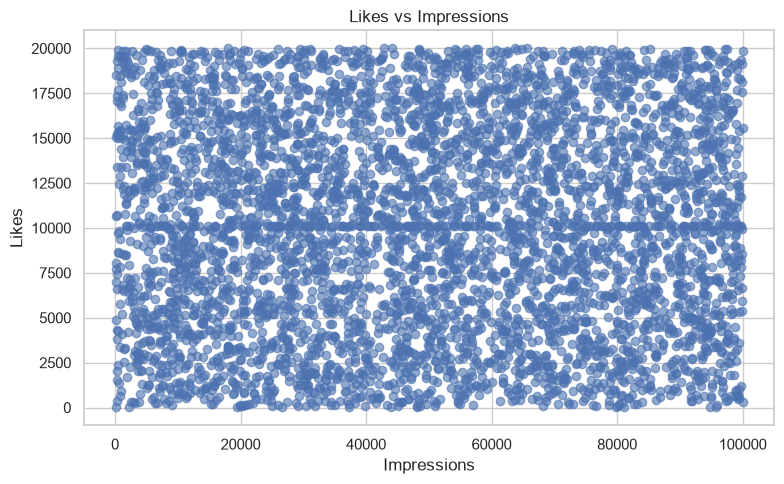

Plot 2 skipped: date column or engagement_score not found.


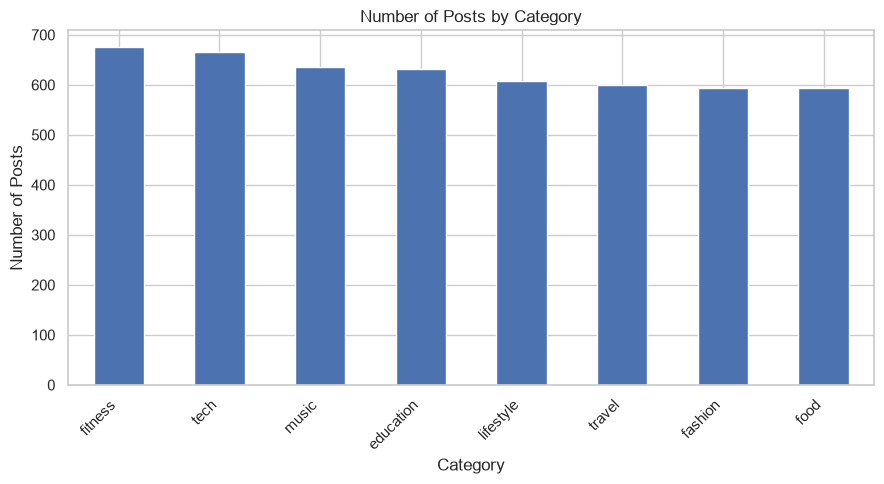

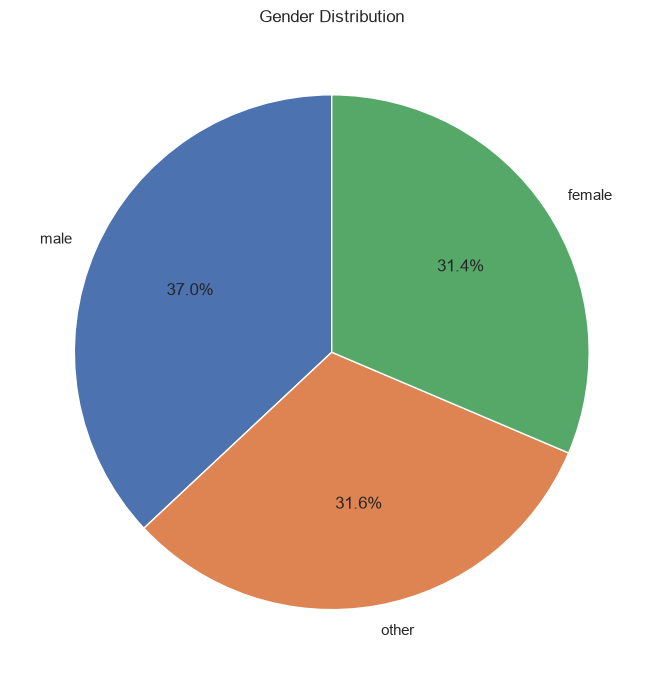

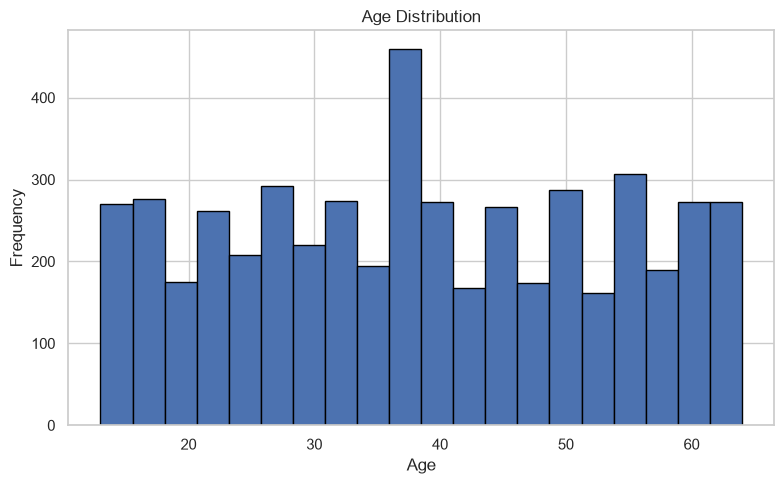

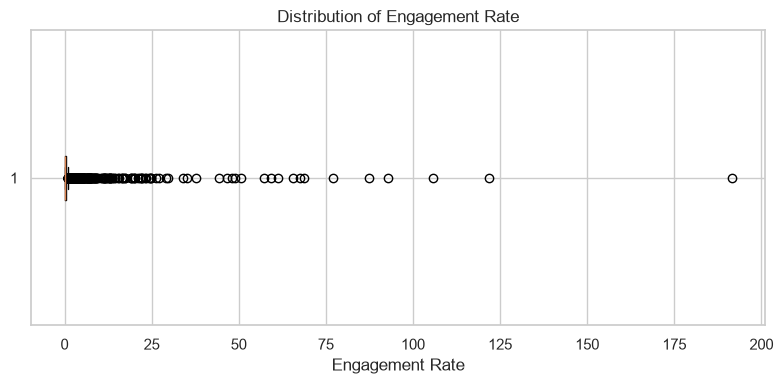

In [27]:
# Plot 1 — Scatter: likes vs impressions (Matplotlib)
if likes_col and impressions_col:
    plt.figure(figsize=(8, 5))
    plt.scatter(df[impressions_col], df[likes_col], alpha=0.6)
    plt.xlabel("Impressions")
    plt.ylabel("Likes")
    plt.title("Likes vs Impressions")
    plt.tight_layout()
    plt.show()
else:
    print("Plot 1 skipped: likes or impressions column not found.")

# Plot 2 — Line: daily engagement trend (Matplotlib)
if impressions_date_col and "engagement_score" in df.columns:
    daily = df.dropna(subset=[impressions_date_col]).groupby(df[impressions_date_col].dt.date)["engagement_score"].mean()
    if not daily.empty:
        plt.figure(figsize=(10, 5))
        plt.plot(daily.index, daily.values, marker="o")
        plt.xlabel("Date")
        plt.ylabel("Average Engagement Score")
        plt.title("Daily Engagement Trend")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
    else:
        print("Plot 2 skipped: no valid dates available.")
else:
    print("Plot 2 skipped: date column or engagement_score not found.")

# Plot 3 — Bar: posts by category (Matplotlib)
if category_col:
    counts = df[category_col].value_counts().head(15)
    counts.plot(kind="bar", figsize=(9, 5), title="Number of Posts by Category")
    plt.xlabel("Category")
    plt.ylabel("Number of Posts")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Plot 3 skipped: category column not found.")

# Plot 4 — Pie: gender distribution (Matplotlib)
if gender_col:
    gender_counts = df[gender_col].value_counts()
    if not gender_counts.empty:
        plt.figure(figsize=(7, 7))
        plt.pie(gender_counts.values, labels=gender_counts.index.astype(str), autopct="%1.1f%%", startangle=90)
        plt.title("Gender Distribution")
        plt.tight_layout()
        plt.show()
else:
    print("Plot 4 skipped: gender column not found.")

# Plot 5 — Histogram: age (Matplotlib)
if age_col:
    plt.figure(figsize=(8, 5))
    plt.hist(df[age_col].dropna(), bins=20, edgecolor="black")
    plt.xlabel("Age")
    plt.ylabel("Frequency")
    plt.title("Age Distribution")
    plt.tight_layout()
    plt.show()
else:
    print("Plot 5 skipped: age column not found.")

# Plot 6 — Box plot: engagement rate (Matplotlib)
if engagement_rate_col:
    plt.figure(figsize=(8, 4))
    plt.boxplot(df[engagement_rate_col].dropna(), vert=False)
    plt.xlabel("Engagement Rate")
    plt.title("Distribution of Engagement Rate")
    plt.tight_layout()
    plt.show()
else:
    print("Plot 6 skipped: engagement rate column not found.")

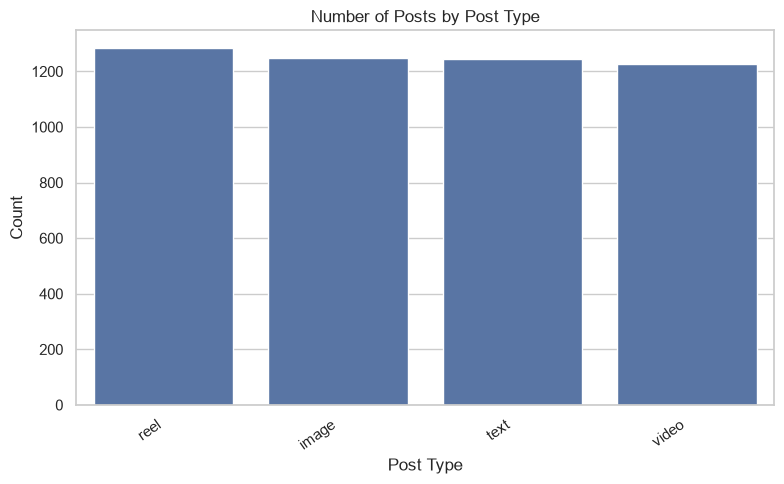

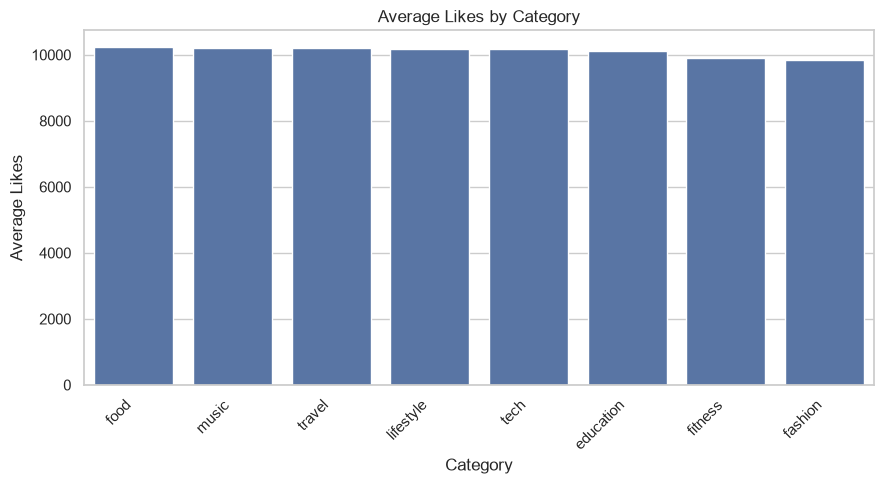

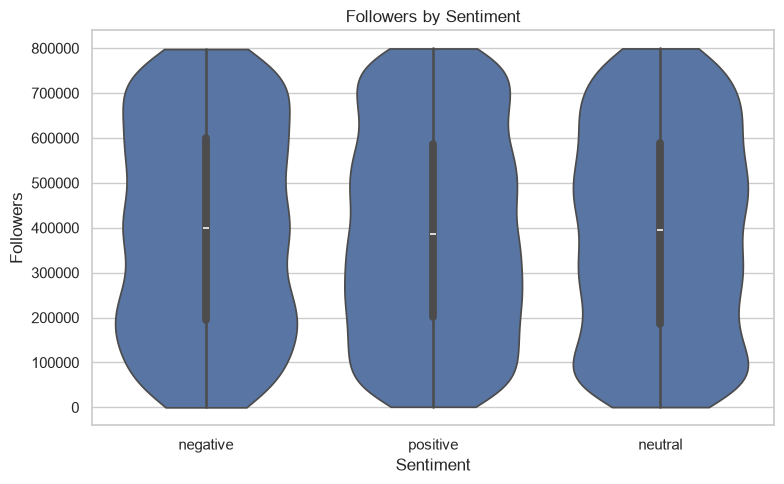

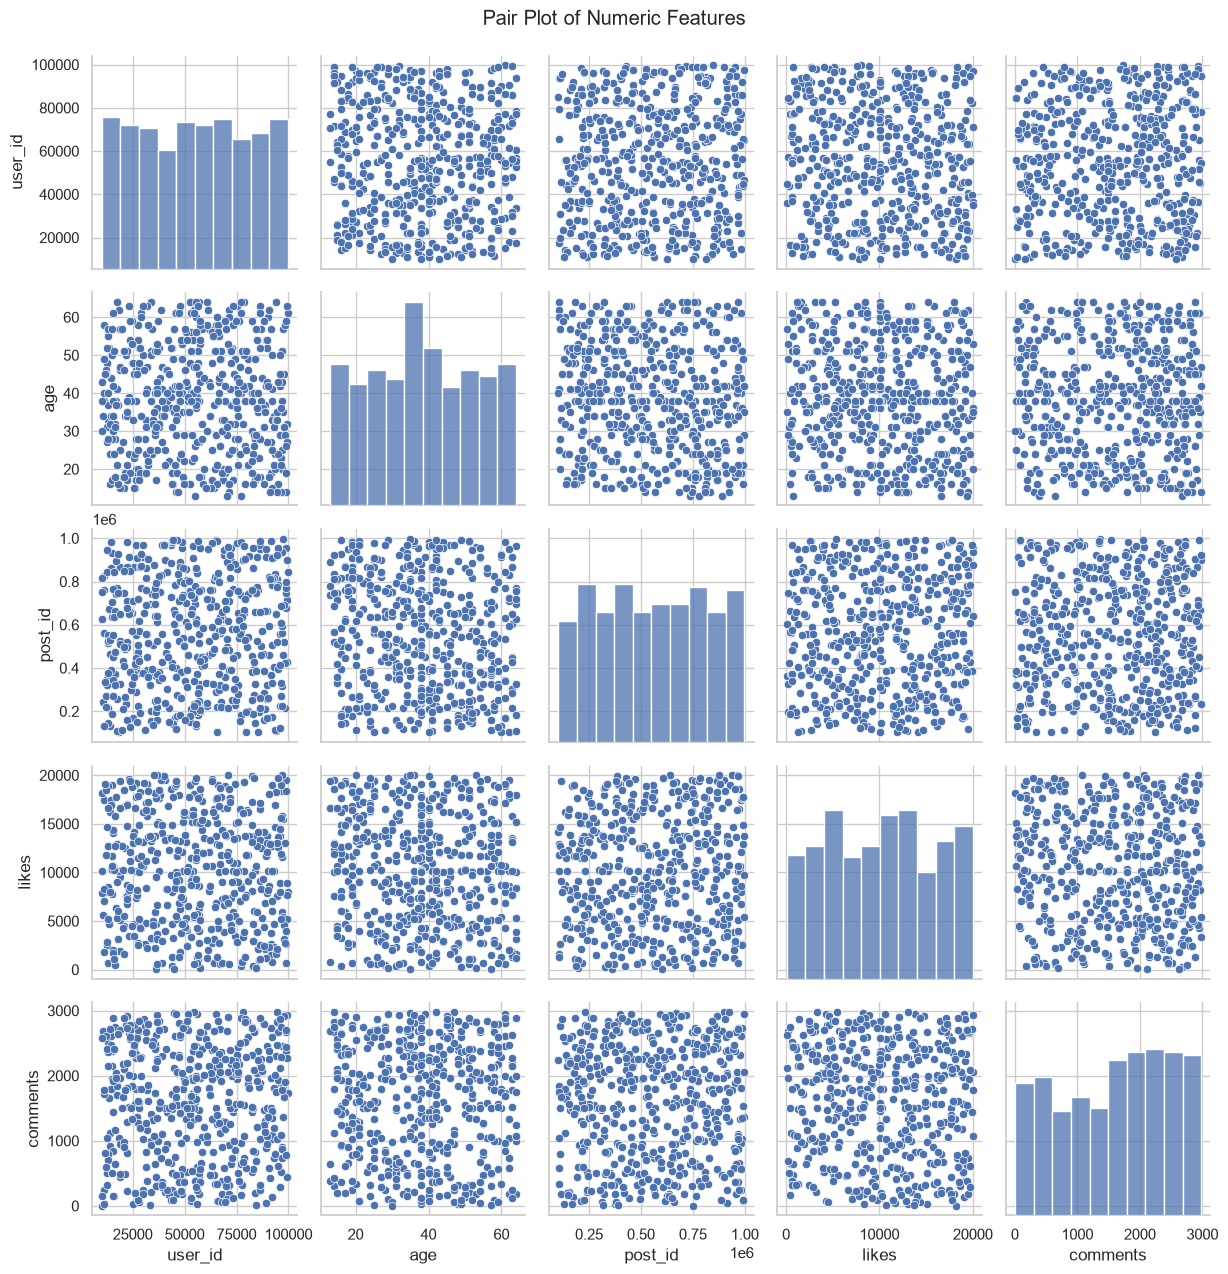

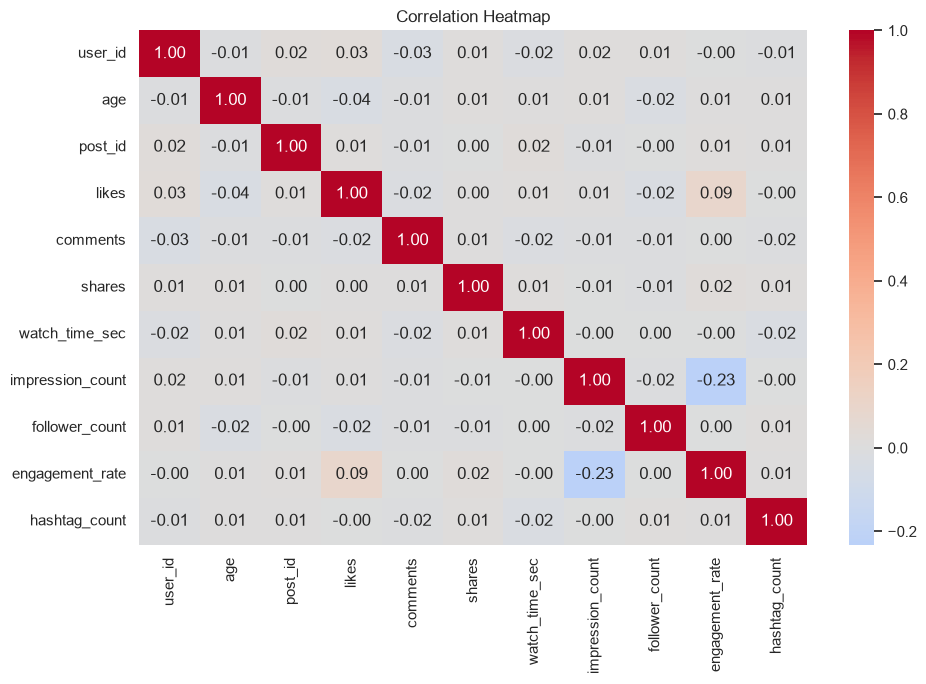

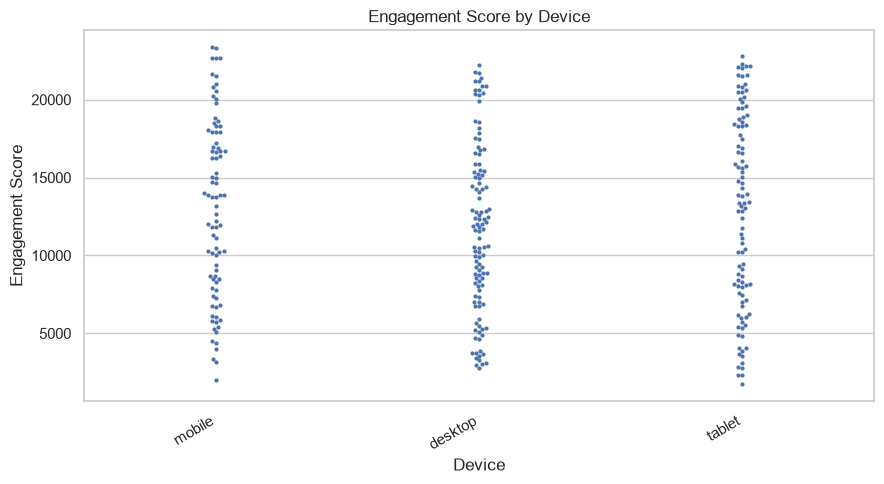

In [28]:
# Plot 7 — Count plot: post type (Seaborn)
if post_type_col:
    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, x=post_type_col, order=df[post_type_col].value_counts().index)
    plt.title("Number of Posts by Post Type")
    plt.xlabel("Post Type")
    plt.ylabel("Count")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Plot 7 skipped: post type column not found.")

# Plot 8 — Bar plot: average likes by category (Seaborn)
if category_col and likes_col:
    category_likes = df.groupby(category_col, dropna=False)[likes_col].mean().sort_values(ascending=False).head(15).reset_index()
    plt.figure(figsize=(9, 5))
    sns.barplot(data=category_likes, x=category_col, y=likes_col)
    plt.title("Average Likes by Category")
    plt.xlabel("Category")
    plt.ylabel("Average Likes")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Plot 8 skipped: category or likes column not found.")

# Plot 9 — Violin: followers by sentiment (Seaborn)
if followers_col and sentiment_col:
    plt.figure(figsize=(8, 5))
    sns.violinplot(data=df, x=sentiment_col, y=followers_col, cut=0)
    plt.title("Followers by Sentiment")
    plt.xlabel("Sentiment")
    plt.ylabel("Followers")
    plt.tight_layout()
    plt.show()
else:
    print("Plot 9 skipped: followers or sentiment column not found.")

# Plot 10 — Pair plot: numeric features (Seaborn)
pair_columns = numeric_df.columns.tolist()[:5]
if len(pair_columns) >= 2:
    pair_data = df[pair_columns].dropna()
    if len(pair_data) > 1:
        pair_plot = sns.pairplot(pair_data.sample(min(len(pair_data), 500), random_state=42))
        pair_plot.fig.suptitle("Pair Plot of Numeric Features", y=1.02)
        plt.show()
    else:
        print("Plot 10 skipped: not enough complete rows.")
else:
    print("Plot 10 skipped: fewer than two numeric features.")

# Plot 11 — Heatmap: correlation matrix (Seaborn)
if not correlation_matrix.empty:
    plt.figure(figsize=(10, 7))
    sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("Plot 11 skipped: correlation matrix unavailable.")

# Plot 12 — Swarm plot: engagement by device (Seaborn)
if device_col and "engagement_score" in df.columns:
    swarm_data = df[[device_col, "engagement_score"]].dropna()
    # Limit rows to keep the swarm plot readable and avoid excessive rendering time.
    if len(swarm_data) > 300:
        swarm_data = swarm_data.sample(300, random_state=42)
    plt.figure(figsize=(9, 5))
    sns.swarmplot(data=swarm_data, x=device_col, y="engagement_score", size=3)
    plt.title("Engagement Score by Device")
    plt.xlabel("Device")
    plt.ylabel("Engagement Score")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Plot 12 skipped: device column or engagement_score not found.")

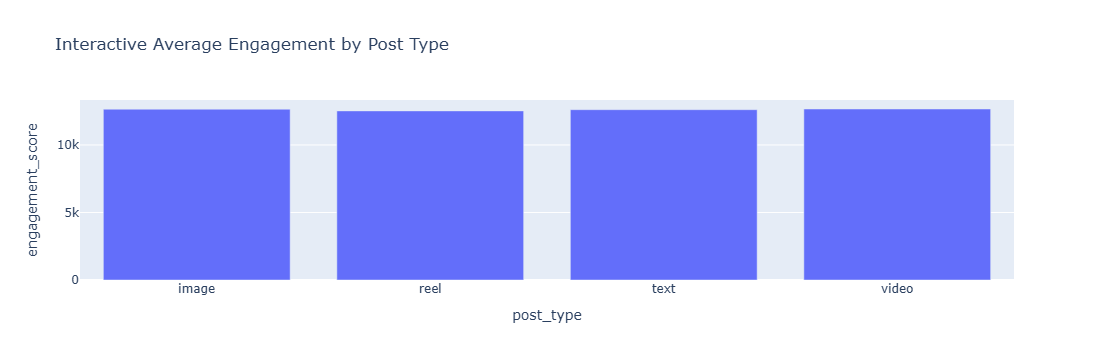

In [30]:
# Plot 13 — Interactive Plotly chart
try:
    import plotly.express as px

    if impressions_date_col and "engagement_score" in df.columns:
        plot_df = df.dropna(subset=[impressions_date_col]).copy()
        plot_df["plot_date"] = plot_df[impressions_date_col].dt.date
        daily_plot = plot_df.groupby("plot_date", as_index=False)["engagement_score"].mean()
        fig = px.line(daily_plot, x="plot_date", y="engagement_score",
                      title="Interactive Daily Average Engagement Score",
                      labels={"plot_date": "Date", "engagement_score": "Average Engagement Score"},
                      markers=True)
        fig.show()
    elif post_type_col and "engagement_score" in df.columns:
        type_plot = df.groupby(post_type_col, as_index=False)["engagement_score"].mean()
        fig = px.bar(type_plot, x=post_type_col, y="engagement_score",
                     title="Interactive Average Engagement by Post Type")
        fig.show()
    elif likes_col and impressions_col:
        fig = px.scatter(df, x=impressions_col, y=likes_col,
                         title="Interactive Likes vs Impressions",
                         hover_data=[c for c in [post_type_col, country_col] if c])
        fig.show()
    else:
        print("Plotly chart skipped: no suitable columns detected.")
except ImportError:
    print("Plotly is not installed. Install it with: pip install plotly")

## Final Insights — Answer the Assignment Questions
The tables below identify the best-performing groups from the dataset. Use the results, not assumptions, when writing the final interpretation.

In [31]:
def ranked_group(group_col, metric_col, label):
    if group_col is None or metric_col is None or metric_col not in df.columns:
        print(f"{label}: cannot calculate because a required column was not detected.")
        return None
    result = df.groupby(group_col, dropna=False)[metric_col].mean().sort_values(ascending=False).to_frame("Average")
    print(f"{label} — highest average first:")
    display(result.head(10))
    if not result.empty:
        print("Top group:", result.index[0], "| Average:", round(float(result.iloc[0, 0]), 3))
    return result

print("CONTENT PERFORMANCE")
ranked_group(post_type_col, "engagement_score" if "engagement_score" in df.columns else engagement_rate_col,
             "Engagement by post type")
ranked_group(category_col, "engagement_score" if "engagement_score" in df.columns else engagement_rate_col,
             "Engagement by category")
ranked_group(country_col, engagement_rate_col, "Average engagement rate by country")

print("\\nUSER TRENDS")
if age_col and engagement_rate_col:
    age_analysis = df.groupby(pd.cut(df[age_col], bins=5), observed=False)[engagement_rate_col].mean().to_frame("Average Engagement Rate")
    display(age_analysis)
else:
    print("Age impact: age or engagement-rate column not found.")

if verified_col and engagement_rate_col:
    verified_analysis = df.groupby(verified_col, dropna=False)[engagement_rate_col].agg(["mean", "median", "count"])
    display(verified_analysis)
else:
    print("Verified-account comparison: verified or engagement-rate column not found.")

print("\\nBEHAVIOURAL INSIGHTS")
if impressions_date_col and impressions_col:
    time_col = next((c for c in df.columns if "hour" in c.lower() or "time_of_day" in c.lower() or "posted_at" in c.lower()), None)
    if time_col:
        display(df.groupby(time_col)[impressions_col].mean().sort_values(ascending=False).to_frame("Average Impressions"))
    elif pd.api.types.is_datetime64_any_dtype(df[impressions_date_col]):
        hour_summary = df.groupby(df[impressions_date_col].dt.hour)[impressions_col].mean().sort_values(ascending=False)
        display(hour_summary.to_frame("Average Impressions by Hour"))
    else:
        print("Posting-time analysis: no usable time field detected.")
else:
    print("Best time for impressions: date/time or impressions column not found.")

if device_col and watch_time_col:
    display(df.groupby(device_col)[watch_time_col].mean().sort_values(ascending=False).to_frame("Average Watch Time"))
else:
    print("Device impact on watch time: device or watch-time column not found.")

print("\\nSENTIMENT ANALYSIS")
ranked_group(sentiment_col, "engagement_score" if "engagement_score" in df.columns else engagement_rate_col,
             "Engagement by sentiment")
if sentiment_col:
    sentiment_counts = df[sentiment_col].value_counts().to_frame("Post Count")
    display(sentiment_counts)
else:
    print("Sentiment distribution: sentiment column not found.")

CONTENT PERFORMANCE
Engagement by post type — highest average first:


,Average
post_type,
video,12664.594286
image,12649.390537
text,12613.243775
reel,12524.031567


Top group: video | Average: 12664.594
Engagement by category — highest average first:


,Average
post_category,
music,12788.549606
food,12739.200675
tech,12686.490226
travel,12650.559167
lifestyle,12639.539539
education,12578.270206
fitness,12457.791852
fashion,12356.420875


Top group: music | Average: 12788.55
Average engagement rate by country — highest average first:


...

,Average Watch Time
device_type,
mobile,4087.830760
tablet,3979.736429
desktop,3974.792521


\nSENTIMENT ANALYSIS
Engagement by sentiment — highest average first:


,Average
sentiment,
negative,12731.498958
positive,12665.799443
neutral,12448.163720


Top group: negative | Average: 12731.499


,Post Count
sentiment,
positive,2513
neutral,1527
negative,960


## One-Page Summary of Findings

Complete this section after running all cells. Replace the prompts with actual values from the output tables; do not report unsupported conclusions.

### 1. Content Performance
- **Highest-engagement post type:** [Insert the top group and its average engagement value.]
- **Best-performing category:** [Insert the category supported by the category summary.]
- **Country with the highest average engagement rate:** [Insert the country and value.]

### 2. User Trends
- **Age and engagement:** [Describe the pattern observed in the age-group analysis.]
- **Verified accounts:** [Compare the mean engagement rates of verified and non-verified accounts.]

### 3. Behavioural Insights
- **Best time for impressions:** [Use the time/hour summary if the dataset includes posting time.]
- **Device and watch time:** [Identify the device group with the highest average watch time.]

### 4. Sentiment Analysis
- **Best-performing sentiment:** [Use the engagement-by-sentiment output.]
- **Negative and neutral posts:** [Compare their engagement and post counts using the results.]

### Conclusion
The analysis used Pandas and NumPy for cleaning and exploration, feature engineering for engagement metrics, descriptive statistics to summarise numerical variables, and Matplotlib, Seaborn, and Plotly for visualisation. The final conclusions should be based on the computed results above.